# Persian Poetry Generation with GPT-2

Fine-tune [`HooshvareLab/gpt2-fa`](https://huggingface.co/HooshvareLab/gpt2-fa) to generate Persian poetry conditioned on a poet's name.

**Project workflow**
1. Load and inspect a Persian poetry corpus.
2. Normalize and format examples with a poet prompt.
3. Tokenize the text and create train/validation splits.
4. Fine-tune a causal language model with Hugging Face `Trainer`.
5. Evaluate validation loss, plot learning curves, and generate sample poems.
6. Save the model and tokenizer so the result can be reloaded later.

> **Important:** Generated poems are model outputs, not authentic quotations. Do not attribute generated lines to the named poet as genuine work.

## 1. Environment and reproducibility

Run this notebook in a Python environment with PyTorch and Transformers installed. A CUDA GPU is recommended for fine-tuning, but the notebook selects CPU automatically when CUDA is unavailable.

For a reproducible project, record the library versions and use the same environment when rerunning the notebook.

In [1]:
import os
import random
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from IPython.display import display, Markdown
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    set_seed,
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: Tesla T4


In [2]:
import html
from IPython.display import HTML, display

NOTEBOOK_CSS = r"""
<style>
:root { --poetry-ink: #25243a; --poetry-muted: #69677b; --poetry-line: #e7e3f2; --poetry-accent: #7157c8; --poetry-soft: #f7f4ff; }
.poetry-banner { direction: ltr; padding: 26px 30px; border-radius: 18px; margin: 12px 0 24px; color: #fff; background: linear-gradient(120deg,#30265f,#7157c8 60%,#b06ab3); box-shadow: 0 8px 24px rgba(65,45,120,.16); }
.poetry-banner h2 { color: #fff; margin: 0 0 8px; font-size: 25px; border: 0; }
.poetry-banner p { margin: 0; opacity: .92; font-size: 14px; }
.poetry-grid { display: grid; grid-template-columns: repeat(auto-fit,minmax(150px,1fr)); gap: 12px; margin: 14px 0 20px; }
.poetry-stat { border: 1px solid var(--poetry-line); border-radius: 14px; padding: 16px; background: linear-gradient(180deg,#fff,#faf8ff); }
.poetry-stat .label { color: var(--poetry-muted); font-size: 12px; margin-bottom: 6px; }
.poetry-stat .value { color: var(--poetry-ink); font-size: 23px; font-weight: 700; overflow-wrap: anywhere; }
.poem-card { direction: rtl; text-align: right; background: linear-gradient(145deg,#fff,#fbf9ff); border: 1px solid var(--poetry-line); border-right: 5px solid var(--poetry-accent); border-radius: 15px; padding: 20px 22px; margin: 14px 0; box-shadow: 0 5px 16px rgba(45,35,90,.055); color: var(--poetry-ink); }
.poem-card .poem-kicker { color: var(--poetry-accent); font-size: 12px; font-weight: 700; margin-bottom: 10px; }
.poem-card .poem-text { white-space: pre-wrap; line-height: 2.15; font-size: 16px; font-family: Tahoma, Arial, sans-serif; }
.poetry-note { border-radius: 10px; background: var(--poetry-soft); border: 1px solid var(--poetry-line); padding: 13px 16px; color: var(--poetry-ink); margin: 12px 0; }
.poetry-table-wrap { overflow-x: auto; border: 1px solid var(--poetry-line); border-radius: 12px; }
.poetry-table { width: 100%; border-collapse: collapse; }
.poetry-table th { background: var(--poetry-soft); text-align: left; padding: 10px; }
.poetry-table td { padding: 10px; border-top: 1px solid var(--poetry-line); }
@media (max-width: 600px) { .poem-card { padding: 15px; } .poetry-banner { padding: 20px; } }
</style>
"""
display(HTML(NOTEBOOK_CSS))
display(HTML("""
<section class="poetry-banner">
  <h2>Persian Poetry Generation · GPT-2</h2>
  <p>Fine-tuning a Persian language model to generate poetry conditioned on a poet's name.</p>
</section>
"""))

def show_stat_cards(items):
    cards = "".join(
        f'<div class="poetry-stat"><div class="label">{html.escape(str(label))}</div>'
        f'<div class="value">{html.escape(str(value))}</div></div>'
        for label, value in items
    )
    display(HTML(f'<div class="poetry-grid">{cards}</div>'))

def show_poem_card(title, poem, poet=None):
    title_html = html.escape(str(title))
    poet_html = f'<div class="poem-kicker">{html.escape(str(poet))}</div>' if poet else ''
    poem_html = html.escape(str(poem))
    display(HTML(
        f'<article class="poem-card">{poet_html}'
        f'<div class="poem-kicker">{title_html}</div>'
        f'<div class="poem-text">{poem_html}</div></article>'
    ))

def show_metric_cards(metrics, title="Training summary"):
    preferred = [
        ("Training loss", metrics.get("train_loss")),
        ("Validation loss", metrics.get("eval_loss")),
        ("Runtime (sec)", metrics.get("train_runtime")),
        ("Samples / sec", metrics.get("train_samples_per_second")),
    ]
    items = [(label, f"{value:.4f}" if isinstance(value, (int, float)) else "—")
             for label, value in preferred if value is not None]
    display(HTML(f'<h3 style="color:#30265f">{html.escape(title)}</h3>'))
    show_stat_cards(items)


## 2. Load the dataset

The notebook uses the public `ChronologicalPersianPoetryDataset` repository. If the dataset is already available locally, set `DATA_DIR` to its directory. Otherwise, the repository is cloned once.

The expected file is `poems.tsv`, with at least `poet` and `poem` columns.

In [3]:
DATA_DIR = Path("poems")
DATA_FILE = DATA_DIR / "poems.tsv"
DATA_REPO = "https://github.com/aghasemi/ChronologicalPersianPoetryDataset.git"

if not DATA_FILE.exists():
    if DATA_DIR.exists():
        raise FileNotFoundError(
            f"Found {DATA_DIR}, but not {DATA_FILE}. Check the dataset directory."
        )
    subprocess.run(["git", "clone", DATA_REPO, str(DATA_DIR)], check=True)

df = pd.read_csv(DATA_FILE, sep="\t")
required_columns = {"poet", "poem"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

df = df.dropna(subset=["poet", "poem"]).copy()
df["poet"] = df["poet"].astype(str).str.strip()
df["poem"] = df["poem"].astype(str).str.strip()
df = df[(df["poet"] != "") & (df["poem"] != "")].reset_index(drop=True)

show_stat_cards([
    ("Usable poems", f"{len(df):,}"),
    ("Unique poets", f"{df['poet'].nunique():,}"),
    ("Dataset columns", f"{len(df.columns):,}"),
])
display(df.head())

,poet,century,poem
0,رودکی,3,گر من این دوستی تو ببرم تا لب گور بزنم نعره...
1,رودکی,3,به حق نالم ز هجر دوست زارا سحرگاهان چو بر گ...
2,رودکی,3,به نام نیک تو، خواجه، فریفته نشوم که نام نی...
3,رودکی,3,دلا، تا کی همی جویی منی را؟ چه داری دوست هر...
4,رودکی,3,گرفت خواهم زلفین عنبرین ترا به بوسه نقش‌کنم...


## 3. Prepare conditional training text

Each training example starts with the poet's name, followed by a separator token and the poem. The model learns to continue the text after this prompt.

- `<|startoftext|>` marks the boundary between the poet name and the poem.
- `<sep>` represents line breaks that were encoded as repeated spaces or tabs in the source corpus.

This formatting teaches the model to condition its continuation on the requested poet. It does not guarantee that the generated style will be historically accurate.

In [4]:
def format_poem_row(row):
    poem = row["poem"].replace("\t", "<sep>").replace("    ", "<sep>")
    return f"{row['poet']}<|startoftext|>{poem}"

df["text"] = df.apply(format_poem_row, axis=1)
poets = sorted(df["poet"].unique().tolist())

sample = df.sample(n=1, random_state=SEED).iloc[0]
show_poem_card("Original dataset sample", sample["poem"][:700], poet=sample["poet"])
display(HTML(
    '<div class="poetry-note"><b>Training format</b><br>'
    '<code>poet name + &lt;|startoftext|&gt; + poem text</code><br>'
    'The poet name acts as a prompt that conditions the generated text.</div>'
))
display(HTML(f'<pre style="white-space:pre-wrap;border:1px solid #e7e3f2;border-radius:10px;padding:14px;background:#fbfaff">{html.escape(sample["text"][:700])}</pre>'))

## 4. Load the tokenizer and base model

We use the Persian GPT-2 checkpoint as the starting point. The two project-specific markers are added as special tokens so the tokenizer can represent them consistently.

After adding tokens, the model's embedding table is resized to match the tokenizer vocabulary.

In [5]:
MODEL_NAME = "HooshvareLab/gpt2-fa"
SPECIAL_TOKENS = {"additional_special_tokens": ["<|startoftext|>", "<sep>"]}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
num_added_tokens = tokenizer.add_special_tokens(SPECIAL_TOKENS)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
if num_added_tokens:
    model.resize_token_embeddings(len(tokenizer))
model.config.pad_token_id = tokenizer.pad_token_id

show_stat_cards([
    ("Tokenizer vocabulary", f"{len(tokenizer):,}"),
    ("New special tokens", num_added_tokens),
    ("Base model", MODEL_NAME),
])

config.json:   0%|          | 0.00/808 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/875k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/14.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/2.75M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  485MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: HooshvareLab/gpt2-fa
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 5. Tokenize and split the dataset

A maximum sequence length of 256 tokens reduces memory use and training time on the Tesla T4. Longer poems may be truncated, so inspect generated samples after training.

The validation split is held out from training. Padding positions are excluded from the language-model loss.

In [6]:
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split

MAX_LENGTH = min(256, int(getattr(model.config, "n_positions", 256)))
VALIDATION_SIZE = 0.10

train_texts, val_texts = train_test_split(
    df["text"].tolist(),
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    shuffle=True,
)

class PoetryDataset(Dataset):
    def __init__(self, texts, tokenizer, max_length=256):
        self.encodings = tokenizer(
            texts,
            truncation=True,
            max_length=max_length,
            padding="max_length",
            return_tensors="pt",
        )
        self.labels = self.encodings["input_ids"].clone()
        self.labels[self.encodings["attention_mask"] == 0] = -100

    def __len__(self):
        return self.encodings["input_ids"].shape[0]

    def __getitem__(self, index):
        return {
            "input_ids": self.encodings["input_ids"][index],
            "attention_mask": self.encodings["attention_mask"][index],
            "labels": self.labels[index],
        }

train_dataset = PoetryDataset(train_texts, tokenizer, MAX_LENGTH)
val_dataset = PoetryDataset(val_texts, tokenizer, MAX_LENGTH)

show_stat_cards([
    ("Training examples", f"{len(train_dataset):,}"),
    ("Validation examples", f"{len(val_dataset):,}"),
    ("Maximum sequence length", MAX_LENGTH),
])

example = train_dataset[0]
display(HTML('<h4 style="color:#30265f">Tokenized training example</h4>'))
display(HTML(f'<pre style="white-space:pre-wrap;border:1px solid #e7e3f2;border-radius:10px;padding:14px;background:#fbfaff">{html.escape(tokenizer.decode(example["input_ids"], skip_special_tokens=False)[:500])}</pre>'))

## 6. Fine-tune the model

These settings are designed for a Google Colab Tesla T4 and a target runtime of roughly 2–4 hours, though actual time depends on GPU availability and evaluation overhead.

- Up to 6 epochs, with a hard cap of 2,500 optimizer steps.
- A 256-token context window to reduce computation; longer poems may be truncated.
- Mixed precision where supported and gradient accumulation for a larger effective batch.
- Evaluation and checkpoint saving every 500 steps, retaining the best checkpoint by validation loss.
- Early stopping if validation loss does not improve for three evaluation rounds.

No single setting guarantees the best literary quality. Review validation loss and generated poems after training.

> **Resource-aware settings:** This notebook uses conservative training settings because free/limited GPU resources (such as a Google Colab Tesla T4) may not have enough memory or time for longer runs. The default maximum sequence length is 256 tokens and training is capped at 2,500 optimizer steps. If you have more GPU memory and compute time, try `MAX_LENGTH = 512`, increase `EPOCHS`, and set `MAX_STEPS = -1` (or raise it) to allow more training. Longer sequences and more training can improve results, but they also increase VRAM use and runtime and do not guarantee better poetry; compare validation loss and generated samples. A positive `MAX_STEPS` overrides the epoch-based duration and may stop training before all configured epochs are completed.


In [9]:
import inspect
import math
from transformers import EarlyStoppingCallback

OUTPUT_DIR = Path("outputs/persian-poetry-gpt2")

# Resource-aware defaults for limited GPU memory/time. Increase these values on stronger hardware.
EPOCHS = 6
MAX_STEPS = 2500  # Positive values cap total optimizer steps and can stop before all epochs finish.
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
WARMUP_STEPS = int(MAX_STEPS * WARMUP_RATIO)

# Conservative settings for a Tesla T4
TRAIN_BATCH_SIZE = 2 if DEVICE == "cuda" else 1
EVAL_BATCH_SIZE = 2 if DEVICE == "cuda" else 1
GRADIENT_ACCUMULATION_STEPS = 8 if DEVICE == "cuda" else 1

# Mixed precision
USE_BF16 = bool(DEVICE == "cuda" and torch.cuda.is_bf16_supported())
USE_FP16 = bool(DEVICE == "cuda" and not USE_BF16)

# Detect argument names supported by the installed Transformers version
training_params = inspect.signature(TrainingArguments.__init__).parameters
strategy_arg = (
    "eval_strategy"
    if "eval_strategy" in training_params
    else "evaluation_strategy"
)

training_args_kwargs = {
    "output_dir": str(OUTPUT_DIR),
    "num_train_epochs": EPOCHS,
    "max_steps": MAX_STEPS,
    "learning_rate": LEARNING_RATE,
    "lr_scheduler_type": "cosine",
    "warmup_steps": WARMUP_STEPS,
    "weight_decay": WEIGHT_DECAY,
    "adam_beta1": 0.9,
    "adam_beta2": 0.999,
    "adam_epsilon": 1e-8,
    "max_grad_norm": 1.0,
    "per_device_train_batch_size": TRAIN_BATCH_SIZE,
    "per_device_eval_batch_size": EVAL_BATCH_SIZE,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "save_strategy": "steps",
    "eval_steps": 500,
    "save_steps": 500,
    "logging_strategy": "steps",
    "logging_steps": 25,
    "save_total_limit": 3,
    "load_best_model_at_end": True,
    "metric_for_best_model": "eval_loss",
    "greater_is_better": False,
    "gradient_checkpointing": (DEVICE == "cuda"),
    "fp16": USE_FP16,
    "bf16": USE_BF16,
    "dataloader_num_workers": 2 if DEVICE == "cuda" else 0,
    "dataloader_pin_memory": (DEVICE == "cuda"),
    "report_to": "none",
    "seed": SEED,
    "data_seed": SEED,
}
training_args_kwargs[strategy_arg] = "steps"

supported_args = {
    key: value
    for key, value in training_args_kwargs.items()
    if key in training_params
}
training_args = TrainingArguments(**supported_args)

# Support different Transformers versions
trainer_params = inspect.signature(Trainer.__init__).parameters
trainer_kwargs = {
    "model": model,
    "args": training_args,
    "train_dataset": train_dataset,
    "eval_dataset": val_dataset,
    "callbacks": [
        EarlyStoppingCallback(
            early_stopping_patience=3,
            early_stopping_threshold=0.0,
        )
    ],
}
if "processing_class" in trainer_params:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in trainer_params:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = Trainer(**trainer_kwargs)

EFFECTIVE_BATCH_SIZE = TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
print(f"Device: {DEVICE}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"Training examples: {len(train_dataset):,}")
print(f"Validation examples: {len(val_dataset):,}")
print(f"Maximum epochs: {EPOCHS}")
print(f"Maximum optimizer steps: {MAX_STEPS}")
print(f"Warmup steps: {WARMUP_STEPS}")
print(f"Train batch per device: {TRAIN_BATCH_SIZE}")
print(f"Gradient accumulation: {GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective batch size (single device): {EFFECTIVE_BATCH_SIZE}")
print(f"Evaluation/checkpoint interval: 500 steps")
print(f"Precision: {'bf16' if USE_BF16 else 'fp16' if USE_FP16 else 'fp32'}")


Device: cuda
GPU: Tesla T4
Training examples: 49,071
Validation examples: 5,453
Maximum epochs: 6
Maximum optimizer steps: 2500
Warmup steps: 150
Train batch per device: 2
Gradient accumulation: 8
Effective batch size (single device): 16
Evaluation/checkpoint interval: 500 steps
Precision: bf16


### Start training

Training stops at the first of these limits: 6 epochs, 2,500 optimizer steps, or early stopping after three consecutive evaluations without improvement. After training, inspect validation loss and generated poems; lower loss alone does not guarantee better poetry.

In [10]:
train_result = trainer.train()
eval_metrics = trainer.evaluate()

summary_metrics = {**train_result.metrics, **eval_metrics}
show_metric_cards(summary_metrics, title="Model training results")
display(pd.DataFrame([
    {"Metric": key, "Value": round(value, 5) if isinstance(value, (int, float)) else value}
    for key, value in summary_metrics.items()
]).style.hide(axis="index").format(precision=5))

Step,Training Loss,Validation Loss
500,5.150493,5.014977
1000,5.057224,4.864920
1500,4.876436,4.790106
2000,4.905397,4.761204
2500,4.870443,4.756688


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


Training Loss,Validation Loss,Step
4.870443,4.756688,2500


Metric,Value
train_runtime,6485.01990
train_samples_per_second,6.16800
train_steps_per_second,0.38600
total_flos,5225840640000000.00000
train_loss,5.08906
epoch,0.81513
eval_loss,4.75669


## 7. Inspect the training curves

The chart helps reveal whether training loss and validation loss move together. A widening gap can be a sign of overfitting, although generated text should also be reviewed qualitatively.

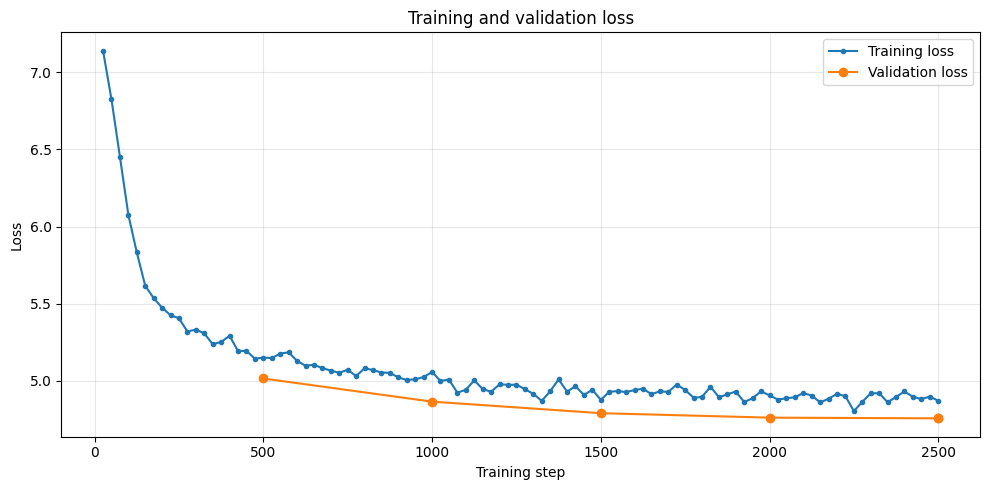

In [11]:
history = pd.DataFrame(trainer.state.log_history)
loss_columns = [column for column in ("loss", "eval_loss") if column in history.columns]

plt.figure(figsize=(10, 5))
if "loss" in history.columns:
    train_log = history.dropna(subset=["loss"])
    plt.plot(train_log["step"], train_log["loss"], marker=".", label="Training loss")
if "eval_loss" in history.columns:
    eval_log = history.dropna(subset=["eval_loss"])
    plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="Validation loss")

plt.title("Training and validation loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Generate poetry from a poet prompt

The generation settings balance variety and repetition:
- `do_sample=True` enables varied continuations.
- `top_p` filters the sampling distribution.
- `repetition_penalty` discourages repetitive output.

The prompt uses the same format as the training examples. Results vary between runs because sampling is enabled.

In [12]:
def generate_poetry(
    poet,
    model=model,
    tokenizer=tokenizer,
    num_return_sequences=3,
    max_new_tokens=100,
    temperature=0.85,
    top_p=0.9,
):
    model.eval()
    prompt = f"{poet}<|startoftext|>"
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            do_sample=True,
            num_return_sequences=num_return_sequences,
            max_new_tokens=max_new_tokens,
            temperature=temperature,
            top_p=top_p,
            repetition_penalty=1.15,
            no_repeat_ngram_size=3,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    poems = []
    for sequence in output_ids:
        text = tokenizer.decode(sequence, skip_special_tokens=False)
        text = text.replace(prompt, "", 1)
        text = text.replace("<sep>", "\n").replace("<|startoftext|>", "")
        text = text.replace("<s>", "").replace("</s>", "").strip()
        poems.append(text)

    for number, poem in enumerate(poems, start=1):
        show_poem_card(f"Generated sample {number}", poem, poet=poet)
    return poems

In [13]:
generated_hafez = generate_poetry("حافظ", num_return_sequences=2)

In [14]:
generated_sohrab = generate_poetry("سهراب سپهری", num_return_sequences=2)

## 9. Save the fine-tuned model

The model and tokenizer are saved together so they can be reloaded without repeating training. The output directory may be large; avoid committing model weights to GitHub unless you intentionally want to distribute them and have checked repository size limits and the model's license.

For a public portfolio, consider publishing the trained model to the Hugging Face Hub and linking to it from the repository README.

In [15]:
FINAL_MODEL_DIR = Path("artifacts/persian-poetry-gpt2")
FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(FINAL_MODEL_DIR))
tokenizer.save_pretrained(str(FINAL_MODEL_DIR))

display(HTML(
    '<div class="poetry-note"><b>Model saved successfully</b><br>'
    f'<code>{html.escape(str(FINAL_MODEL_DIR.resolve()))}</code><br>'
    'The directory contains the fine-tuned weights and tokenizer files.</div>'
))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 10. Reload and test the saved model

This final check verifies that the saved artifacts can be loaded again. It is useful when sharing the project or running inference separately from training.

In [16]:
reloaded_tokenizer = AutoTokenizer.from_pretrained(FINAL_MODEL_DIR)
reloaded_model = AutoModelForCausalLM.from_pretrained(FINAL_MODEL_DIR)
reloaded_model.to(DEVICE)

_ = generate_poetry(
    "شهریار",
    model=reloaded_model,
    tokenizer=reloaded_tokenizer,
    num_return_sequences=1,
)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

## 11. Limitations and next steps

- **Data quality:** the corpus may contain inconsistent line breaks, spelling variants, or metadata errors.
- **Attribution:** generated text can resemble a poet's style but is not necessarily written by that poet.
- **Evaluation:** validation loss measures next-token prediction, not literary quality. Human review is useful for coherence, originality, repetition, and Persian fluency.
- **Reproducibility:** record the Python and library versions, random seed, dataset revision, and training configuration.
- **Experiments worth adding:** compare the base model with the fine-tuned model using identical prompts; try different maximum sequence lengths and learning rates; compare outputs with and without repetition controls.
- **Responsible sharing:** review dataset and model licenses before redistribution, and do not commit private data or large model weights unintentionally.
- **Training configuration:** the notebook uses up to 12 epochs with early stopping based on validation loss. The best literary output may require comparing several learning rates and generation settings; validation loss is only a proxy.
